## Outline

1. Locate and import `confusion_matrix.py`.
2. Configure the CSV filename and label columns.
3. Generate and display the confusion matrix.
4. Try a different number of classes and review common pitfalls.


In [1]:
# Run this only if the required packages are not installed.
# %pip install -r ../requirements.txt

from pathlib import Path
import sys

# Open this notebook from the folder containing confusion_matrix.py.
NOTEBOOK_DIR = Path.cwd()
SCRIPT_PATH = NOTEBOOK_DIR / "confusion_matrix.py"
if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {SCRIPT_PATH}. Open this notebook from the confusion-matrix folder."
    )

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from confusion_matrix import infer_labels, main, read_label_rows


## Step 1 - Configure the input

Set `filename` to a CSV file in this folder or provide a full path. The two column names must match the CSV header exactly. Set `filename`, `true_column`, and `predicted_column` to `None` if you want `main()` to ask for them interactively.

The `labels` option is normally left as `None`; use an explicit list when a class has no predicted samples or when you need a specific class order.

In [2]:
# Example input generated for the five-class demo.
filename = "confusion_matrix_demo_5class.csv"

true_column = "true_label"
predicted_column = "predicted_label"

# Leave as None to infer class order from the data.
# Example explicit order: labels = ["Class_A", "Class_B", "Class_C", "Class_D", "Class_E"]
labels = None

output_prefix = None  # None creates <CSV name>_confusion_matrix.png/.pdf
title = None          # Optional figure title; None keeps the figure publication-clean
font_family = "DejaVu Sans"


## Step 2 - Generate the figure

The axes are fixed as **True label** (rows) and **Predicted label** (columns). Each cell shows the raw count on the first line and the row percentage in parentheses on the second line.

PNG saved to: confusion_matrix_demo_5class_confusion_matrix.png
PDF saved to: confusion_matrix_demo_5class_confusion_matrix.pdf


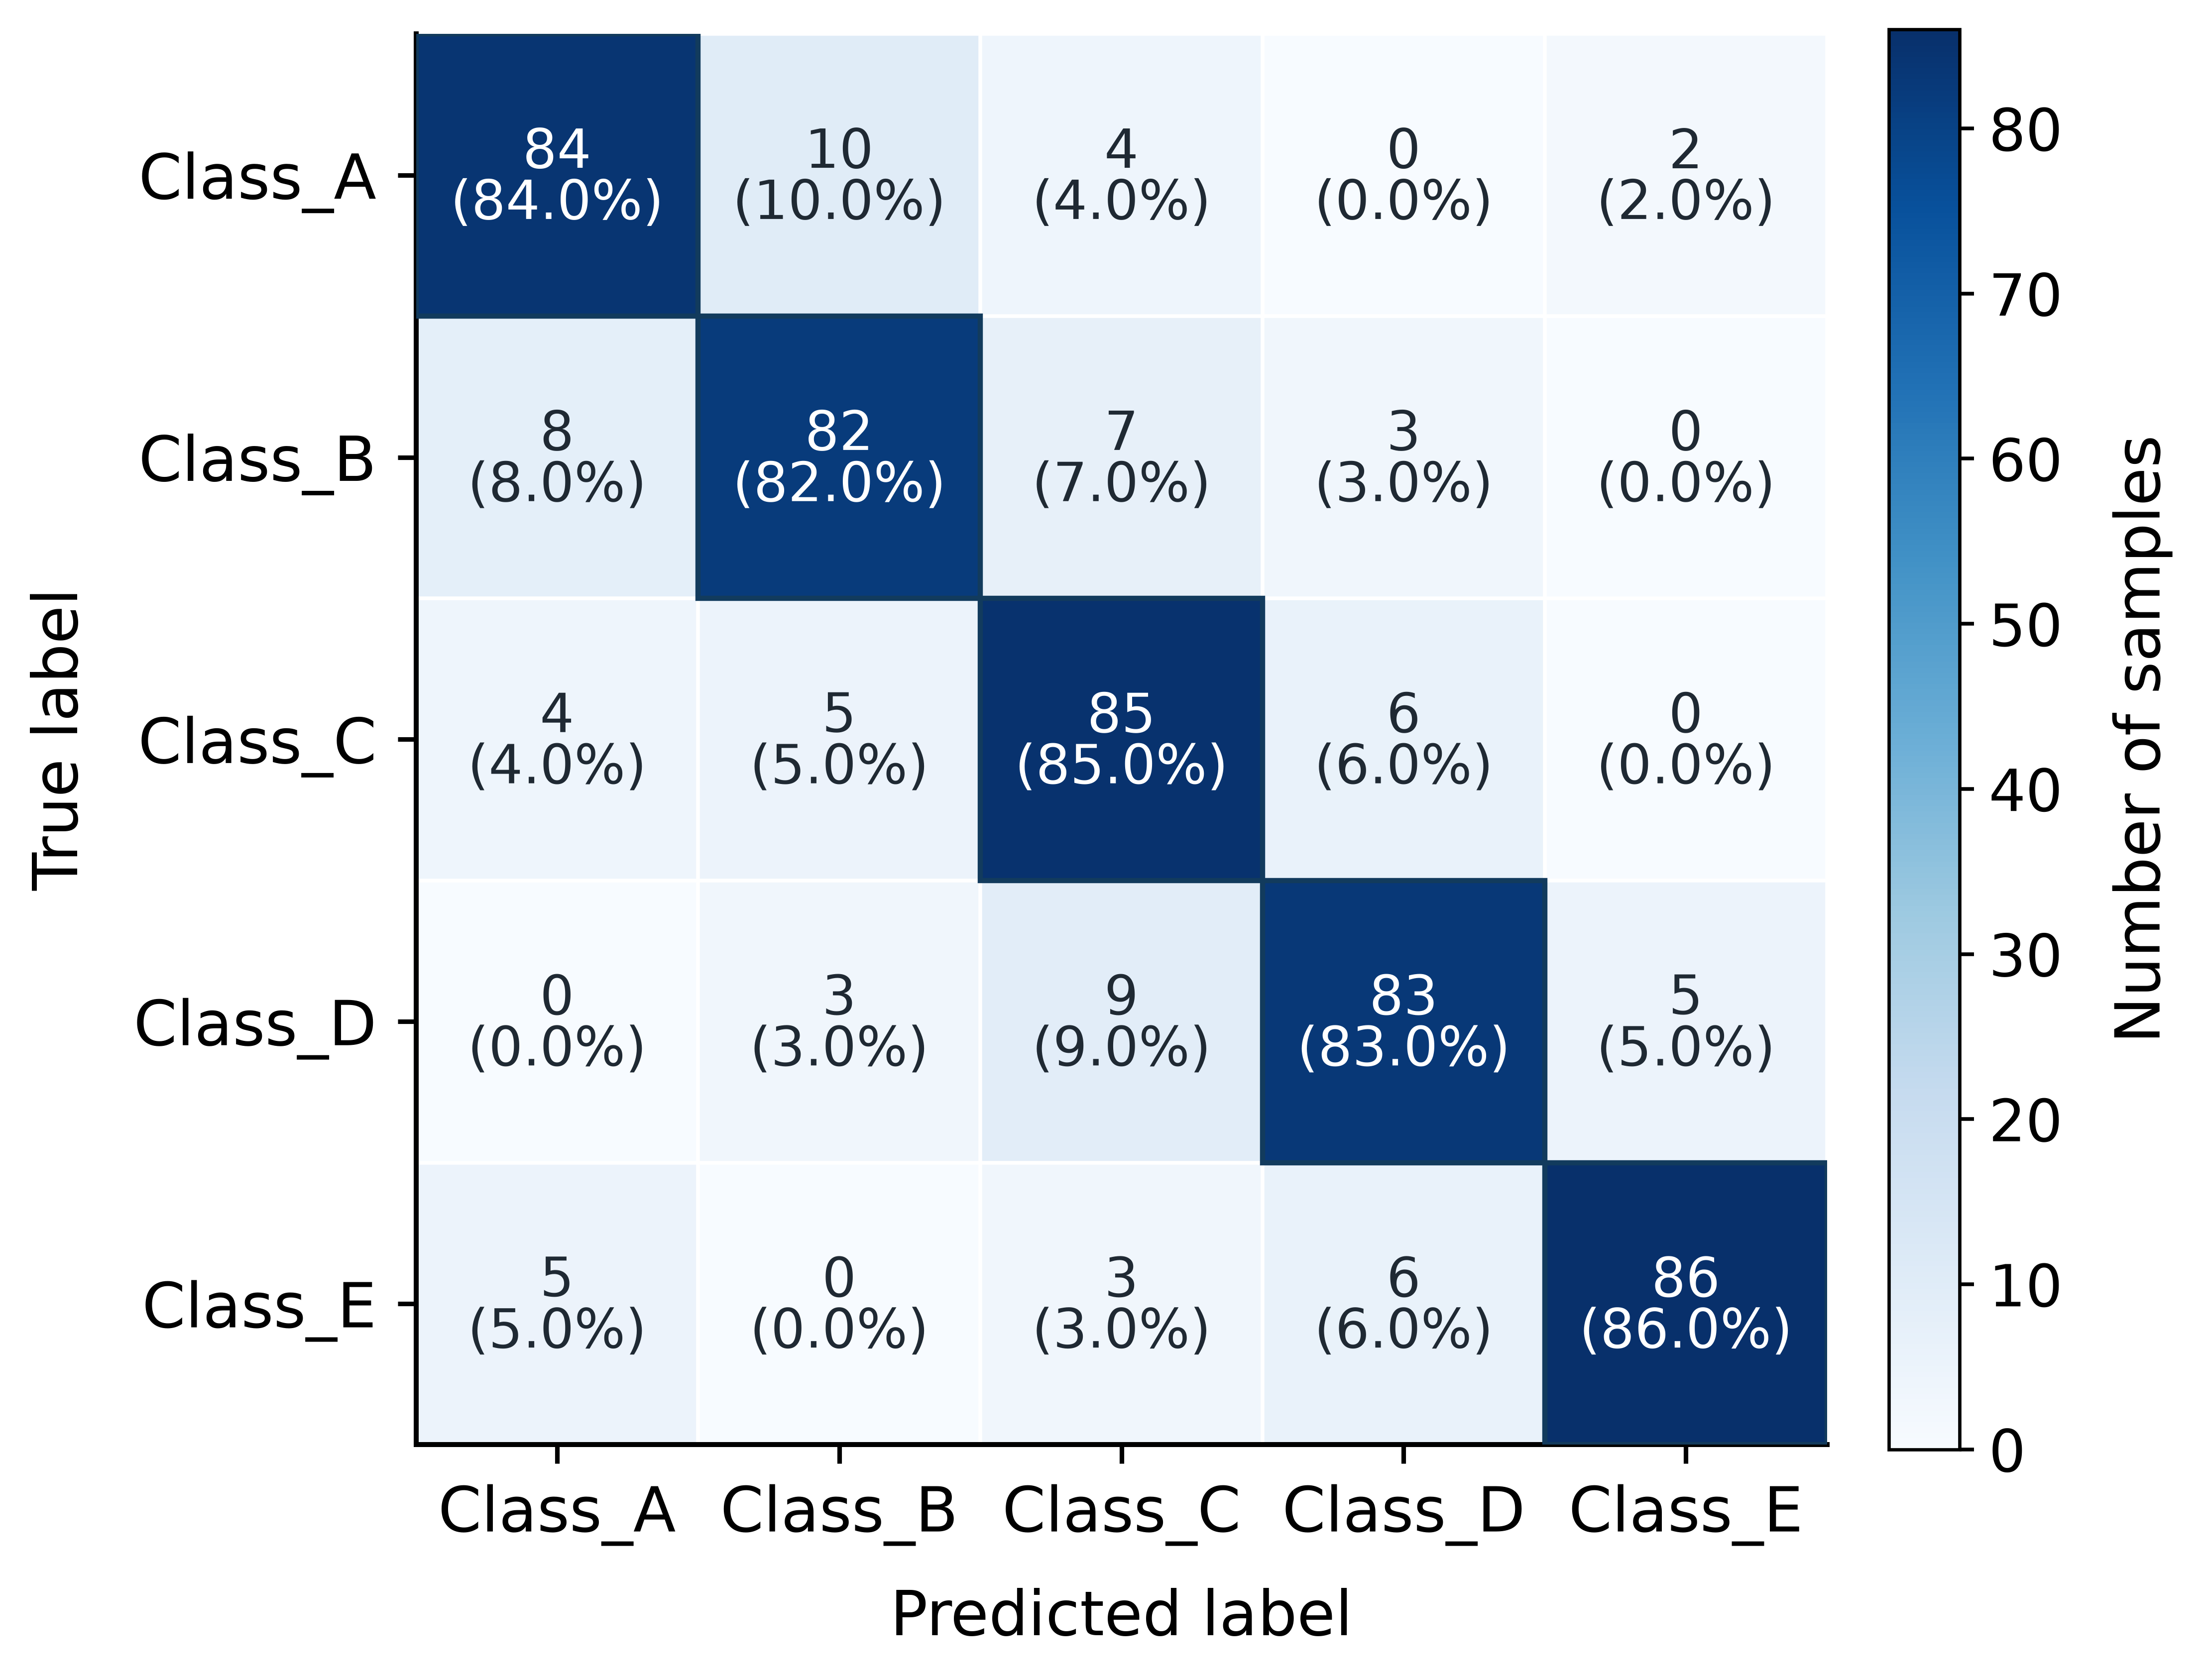

In [3]:
from IPython.display import Image, display

status = main(
    input_csv=filename,
    output_prefix=output_prefix,
    true_column=true_column,
    predicted_column=predicted_column,
    labels=labels,
    font_family=font_family,
    title=title,
)
if status == 0:
    prefix = Path(output_prefix) if output_prefix else Path(filename).with_name(f"{Path(filename).stem}_confusion_matrix")
    display(Image(filename=f"{prefix}.png", width=650))

In [4]:
# Compact data check: confirm the number and order of classes used.
input_path = Path(filename).expanduser()
rows = read_label_rows(
    input_path, true_column, predicted_column, require_matching_label_sets=not labels
)
class_order = labels or infer_labels(rows)
print(f"Samples: {len(rows)}")
print(f"Classes ({len(class_order)}): {class_order}")


Samples: 500
Classes (5): ['Class_A', 'Class_B', 'Class_C', 'Class_D', 'Class_E']


## Output files

The files are saved beside the CSV unless `output_prefix` is changed:

- `<CSV name>_confusion_matrix.png` - 600-dpi raster figure.
- `<CSV name>_confusion_matrix.pdf` - vector figure for manuscripts or slides.


## Exercise: use a different number of classes

Try the notebook with the bundled `confusion_matrix_demo_3class.csv` or `confusion_matrix_demo_10class.csv`, or with your own four- or eight-class CSV. Change only `filename`, `true_column`, and `predicted_column`; the plotting code does not need to change. If a class is absent from the prediction column, provide the complete class order through `labels`.

Common pitfall: the column names are case-sensitive. If the script reports a missing column, inspect the first row of the CSV and copy the header exactly.

In [5]:
# Exercise scaffold - edit these values, then re-run the generation cell.
# filename = "my_8_class_results.csv"
# true_column = "actual_class"
# predicted_column = "model_prediction"
# labels = ["A", "B", "C", "D", "E", "F", "G", "H"]
